# Importación de librerías, carga de base de Datos y examen de la misma


In [20]:
pip install numpy pandas matplotlib scipy statsmodels openpyxl 

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
# %% Importación de paquetes ============================

# Trabajar con rutas relativas en python
from pathlib import Path

# Módulos de numpy, pandas, matplotlib y scipy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import jarque_bera, probplot

# Módulos de statsmodels
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from scipy import stats
#modulos matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker

import os
import subprocess
import urllib.request
import zipfile
from pathlib import Path

In [22]:

# %% Cargar bases de datos en python usando rutas relativas =========================

# Obtener la ruta del directorio actual de trabajo
BASE_DIR = Path.cwd()

# Ruta de las bases de datos
ruta_exp = BASE_DIR / "Demanda de Energía del SIN.xlsx" # Base de datos
# Usamos read_excel eliminando las primeras 2 filas de la base de datos.
datos = pd.read_excel(ruta_exp, header=2 )

# Ver el tipo de objeto de la base de datos (Pandas.DataFrame)
print(type(datos))
datos.head()

<class 'pandas.core.frame.DataFrame'>


,Date - Year,Date - Month,Date - Day,Suma de Demanda Energia SIN
0,2000,January,1,88.141870
1,2000,January,2,89.124367
2,2000,January,3,106.186255
3,2000,January,4,109.554603
4,2000,January,5,109.348213


In [23]:
# %% Creación del índice temporal de las series de tiempo uniendo las columnas de año meses y dias

# 1. Crear la columna única de fecha a partir de Año, Mes y Día
fecha_texto = datos['Date - Year'].astype(str) + '-' + datos['Date - Month'].astype(str) + '-' + datos['Date - Day'].astype(str)
datos['Date'] = pd.to_datetime(fecha_texto, format='%Y-%B-%d')

# 2. Reemplazar y eliminar las 3 columnas antiguas de año, mes y día
datos = datos.drop(columns=['Date - Year', 'Date - Month', 'Date - Day'])

# 3. Establecer la nueva columna de fecha como el índice del DataFrame
datos = datos.set_index('Date')
# ==========%% Creación de la serie de tiempo de "demanda"%%==============#

serie = datos["Suma de Demanda Energia SIN"].copy()
serie = pd.to_numeric(serie, errors="coerce")
serie = serie.dropna() # Borrar missing values

# El tipo de objeto de la base de datos ahora es un Pandas.Series
print(type(serie))

# Ver algunas estadísticas descriptivas de la serie de tiempo
print(serie.describe())

serie_trimestral = serie.resample('QE').sum()

print("\n--- Vista previa de la serie trimestral corregida ---")
print(serie_trimestral.head())

# 4. Aplicar logaritmo
log_serie_trimestral = np.log(serie_trimestral)
print("\n--- Vista previa de log_serie_trimestral corregida ---")
print(log_serie_trimestral.head())

<class 'pandas.core.series.Series'>
count    9497.000000
mean      167.177893
std        35.640387
min        86.794068
25%       136.799370
50%       163.544329
75%       194.047828
max       249.800418
Name: Suma de Demanda Energia SIN, dtype: float64

--- Vista previa de la serie trimestral corregida ---
Date
2000-03-31    10127.707299
2000-06-30    10168.398813
2000-09-30    10434.087598
2000-12-31    10748.652550
2001-03-31    10482.415161
Freq: QE-DEC, Name: Suma de Demanda Energia SIN, dtype: float64

--- Vista previa de log_serie_trimestral corregida ---
Date
2000-03-31    9.223030
2000-06-30    9.227040
2000-09-30    9.252833
2000-12-31    9.282536
2001-03-31    9.257454
Freq: QE-DEC, Name: Suma de Demanda Energia SIN, dtype: float64


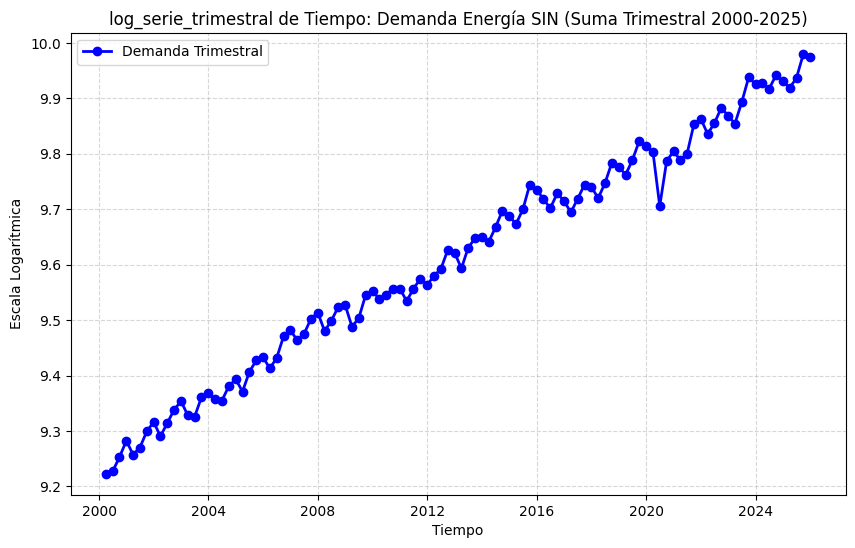

In [24]:
# ==========%% Gráfica de la serie trimestral corregida %%==============#
plt.figure(figsize=(10, 6))
plt.plot(log_serie_trimestral, color='blue', linewidth=2, marker='o', label='Demanda Trimestral')
plt.title('log_serie_trimestral de Tiempo: Demanda Energía SIN (Suma Trimestral 2000-2025)')
plt.xlabel('Tiempo')
plt.ylabel('Escala Logarítmica')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

# Identificación

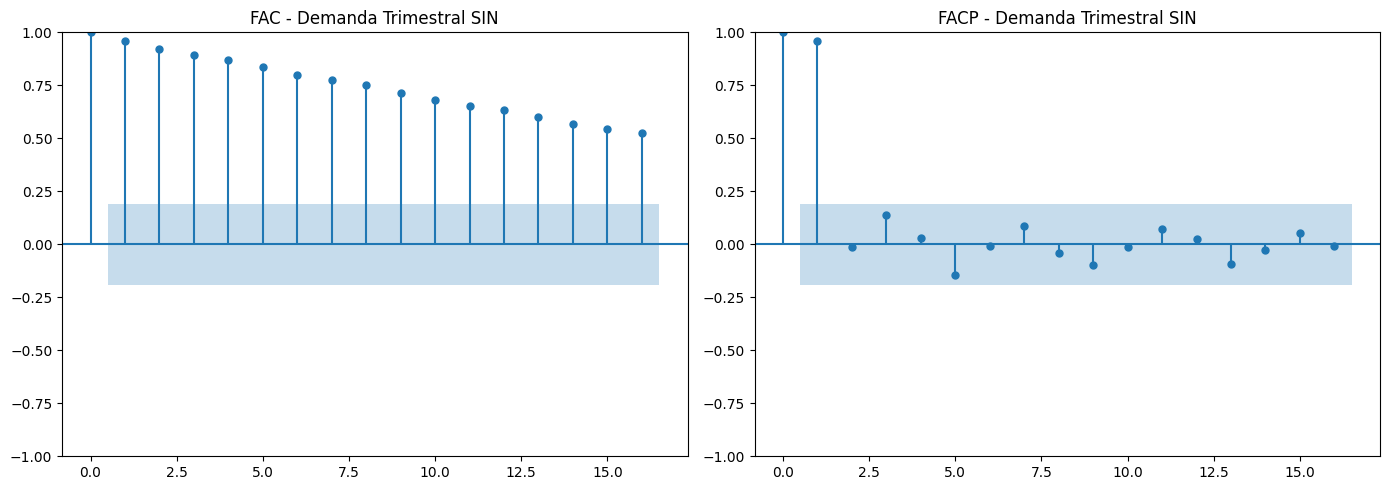

In [25]:
# %% FAC y FACP de la serie_trimestral original
# ==========%% FAC y FACP: serie Trimestral %%==============#
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(log_serie_trimestral, lags=16, alpha=0.05, bartlett_confint=False, ax=axes[0])
axes[0].set_title("FAC - Demanda Trimestral SIN")

plot_pacf(log_serie_trimestral, lags=16, alpha=0.05, method='ywm', ax=axes[1])
axes[1].set_title("FACP - Demanda Trimestral SIN")

plt.tight_layout()
plt.show()

In [26]:
def evaluar_estacionariedad(serie_trimestral, alpha=0.05):
    """
    Ejecuta y evalúa conjuntamente las pruebas ADF (Augmented Dickey-Fuller)
    y KPSS (Kwiatkowski-Phillips-Schmidt-Shin).
    """
    print("=" * 60)
    print("PRUEBAS DE ESTACIONARIEDAD")
    print("=" * 60)

    # 1.1 Test ADF (H0: La serie_trimestral TIENE raíz unitaria / NO es estacionaria)
    adf_res = adfuller(log_serie_trimestral.dropna(), autolag='AIC')
    p_adf = adf_res[1]

    # 1.2 Test KPSS (H0: La serie_trimestral ES estacionaria alrededor de una constante)
    # catch_warnings ignora advertencias por p-valores fuera del rango tabulado
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kpss_res = kpss(log_serie_trimestral.dropna(), regression='c', nlags="auto")
    p_kpss = kpss_res[1]

    print(f"ADF Statistic: {adf_res[0]:.4f} | p-value: {p_adf:.4f}")
    print(f"KPSS Statistic: {kpss_res[0]:.4f} | p-value: {p_kpss:.4f}\n")

    # Diagnóstico combinado
    if p_adf < alpha and p_kpss >= alpha:
        print("-> CONCLUSIÓN: La serie_trimestral es ESTACIONARIA (ADF rechaza H0, KPSS no rechaza H0).")
    elif p_adf >= alpha and p_kpss < alpha:
        print("-> CONCLUSIÓN: La serie_trimestral NO ES ESTACIONARIA (Raíz unitaria presente). Se requiere diferenciar (d >= 1).")
    elif p_adf >= alpha and p_kpss >= alpha:
        print("-> CONCLUSIÓN: RESULTADO INCONCLUSO / Indiferente. Evaluar transformaciones o diferencias.")
    else:
        print("-> CONCLUSIÓN: Estacionariedad en tendencia (Difference stationary vs Trend stationary). Considere evaluar diferenciación o restar tendencia.")

# Ejecutar diagnóstico de estacionariedad
evaluar_estacionariedad(log_serie_trimestral)

PRUEBAS DE ESTACIONARIEDAD
ADF Statistic: -0.5429 | p-value: 0.8834
KPSS Statistic: 1.5837 | p-value: 0.0100

-> CONCLUSIÓN: La serie_trimestral NO ES ESTACIONARIA (Raíz unitaria presente). Se requiere diferenciar (d >= 1).


C:\Users\Kayak\AppData\Local\Temp\ipykernel_11204\708508513.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_res = adfuller(log_serie_trimestral.dropna(), autolag='AIC')


PRUEBAS DE ESTACIONALIDAD (Periodo asumido: 4)
Fuerza de la Estacionalidad (Fs): 0.7324
-> CONCLUSIÓN: Existe una ESTACIONALIDAD FUERTE (Fs > 0.6).
Kruskal-Wallis Stat: 67.5716 | p-value: 0.0000
-> CONCLUSIÓN: Diferencias estacionales altamente SIGNIFICATIVAS entre grupos.



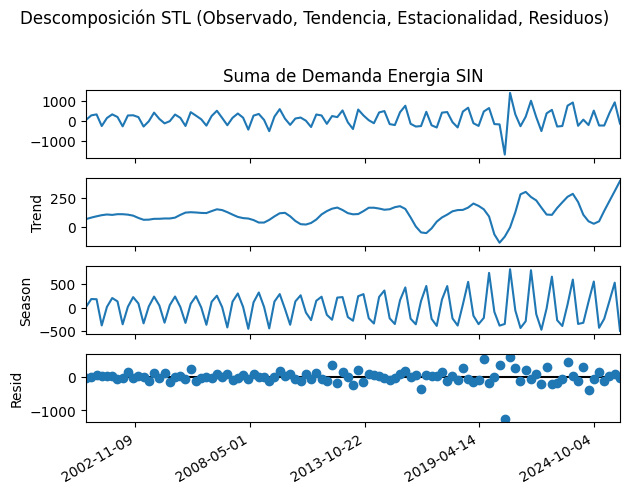

In [27]:


def evaluar_estacionalidad(serie_trimestraldif, periodo=3, alpha=0.05):
    """
    Evalúa la presencia de estacionalidad mediante:
    1. Descomposición STL y cálculo de la Fuerza de Estacionalidad (Fs).
    2. Prueba no paramétrica de Kruskal-Wallis entre ciclos.
    3. Inspección gráfica de descomposición STL y funciones ACF/PACF.
    """
    print("=" * 60)
    print(f"PRUEBAS DE ESTACIONALIDAD (Periodo asumido: {periodo})")
    print("=" * 60)

    df_clean = serie_trimestraldif.dropna()

    # 3.1 Descomposición STL
    stl_fit = STL(df_clean, period=periodo).fit()

    # Fuerza de la Estacionalidad (Fs)
    var_resid = np.var(stl_fit.resid)
    var_seas_resid = np.var(stl_fit.seasonal + stl_fit.resid)
    fuerza_estacional = max(0, 1 - (var_resid / var_seas_resid)) if var_seas_resid > 0 else 0

    print(f"Fuerza de la Estacionalidad (Fs): {fuerza_estacional:.4f}")
    if fuerza_estacional > 0.6:
        print("-> CONCLUSIÓN: Existe una ESTACIONALIDAD FUERTE (Fs > 0.6).")
    elif fuerza_estacional > 0.3:
        print("-> CONCLUSIÓN: Existe una ESTACIONALIDAD MODERADA.")
    else:
        print("-> CONCLUSIÓN: Estacionalidad DÉBIL o no significativa.")

    # 3.2 Prueba de Kruskal-Wallis según el periodo
    if isinstance(df_clean.index, pd.DatetimeIndex):
        if periodo == 4:      # Datos trimestrales agrupados por año (1, 2, 3, 4)
            grupos = [group.values for _, group in df_clean.groupby(df_clean.index.quarter)]
        elif periodo == 2:    # Datos trimestrales agrupados por semestre
            grupos = [group.values for _, group in df_clean.groupby(df_clean.index.dayofweek)]
        elif periodo == 3:    # Datos trimestrales agrupados por semestre
            grupos = [group.values for _, group in df_clean.groupby(df_clean.index.dayofweek)]
        else:
            grupos = None

        if grupos and len(grupos) > 1:
            kw_stat, p_kw = stats.kruskal(*grupos)
            print(f"Kruskal-Wallis Stat: {kw_stat:.4f} | p-value: {p_kw:.4f}")
            if p_kw < alpha:
                print("-> CONCLUSIÓN: Diferencias estacionales altamente SIGNIFICATIVAS entre grupos.\n")
            else:
                print("-> CONCLUSIÓN: No se detectan diferencias significativas entre grupos.\n")

    # 3.3 Gráficos STL
    fig_stl = stl_fit.plot()
    fig_stl.suptitle("Descomposición STL (Observado, Tendencia, Estacionalidad, Residuos)", fontsize=12, y=1.02)

    for ax in fig_stl.axes:
        ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=6))

    fig_stl.autofmt_xdate()
    fig_stl.tight_layout()
    plt.show()

# ==========================================
# Ejecución correcta
# ==========================================
# 1. Crear la serie diferenciada
serie_trimestraldif = serie_trimestral.diff().dropna()

# 2. Ejecutar prueba con periodo=4 para datos trimestrales
evaluar_estacionalidad(serie_trimestraldif, periodo=4)

In [28]:

#desestacionalizar con x13
try:
    from statsmodels.tsa.x13 import x13_arima_analysis
    res_x13 = x13_arima_analysis(log_serie_trimestral, outlier=True, trading=False)
    log_serie_desestacionalizada = res_x13.seasadj
except Exception:
    from statsmodels.tsa.seasonal import STL
    stl = STL(log_serie_trimestral, period=4).fit()
    log_serie_desestacionalizada = log_serie_trimestral - stl.seasonal

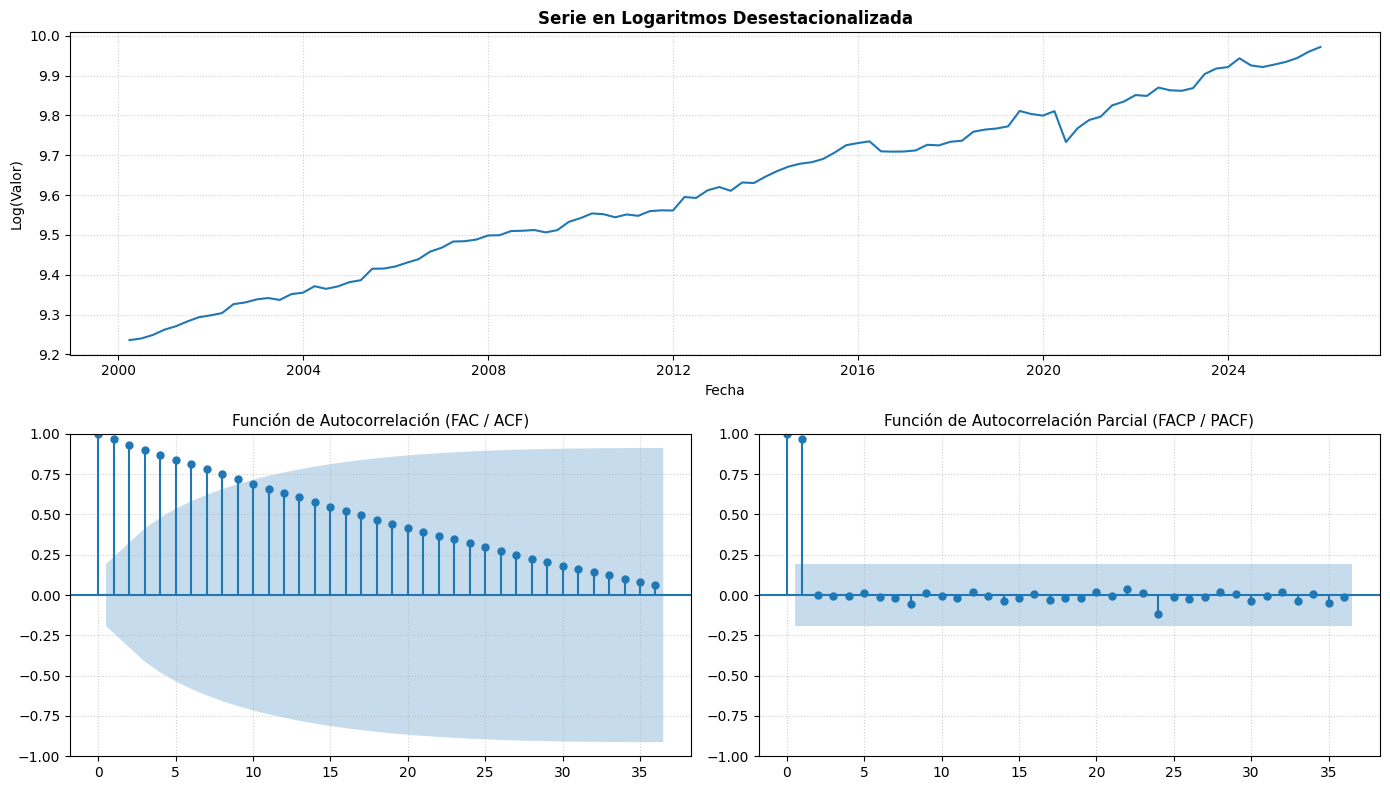

In [29]:
# %% =========================================================================
# VISUALIZACIÓN DE SERIE LOG-DESESTACIONALIZADA, FAC Y FACP
# =========================================================================

import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Limpieza previa de posibles valores nulos
serie_clean = log_serie_desestacionalizada.dropna()

# Definición de la figura
fig = plt.figure(figsize=(14, 8))

# 1. Gráfico superior: Serie de tiempo
ax1 = plt.subplot2grid((2, 2), (0, 0), colspan=2)
ax1.plot(serie_clean, color='tab:blue', linewidth=1.5)
ax1.set_title("Serie en Logaritmos Desestacionalizada", fontsize=12, fontweight='bold')
ax1.set_xlabel("Fecha")
ax1.set_ylabel("Log(Valor)")
ax1.grid(True, linestyle=':', alpha=0.6)

# 2. Gráfico inferior izquierdo: FAC (ACF)
ax2 = plt.subplot2grid((2, 2), (1, 0))
plot_acf(serie_clean, lags=36, ax=ax2, alpha=0.05)
ax2.set_title("Función de Autocorrelación (FAC / ACF)", fontsize=11)
ax2.grid(True, linestyle=':', alpha=0.6)

# 3. Gráfico inferior derecho: FACP (PACF)
ax3 = plt.subplot2grid((2, 2), (1, 1))
plot_pacf(serie_clean, lags=36, ax=ax3, alpha=0.05, method='ywm')
ax3.set_title("Función de Autocorrelación Parcial (FACP / PACF)", fontsize=11)
ax3.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [30]:
# %% =========================================================================
# 3. BÚSQUEDA MANUAL (GRID SEARCH) PARA SERIE DESESTACIONALIZADA
# =========================================================================
import itertools
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX

# 1. Definir rangos de búsqueda únicamente para p y q
p_range = range(0, 4)
q_range = range(0, 4)

d_fijo = 1  # Diferenciación regular si la serie en logaritmos tiene tendencia

mejores_resultados = []

# 2. Bucle de optimización ARIMA (p, d, q)
for p, q in itertools.product(p_range, q_range):
    try:
        mod = SARIMAX(
            log_serie_desestacionalizada,
            order=(p, d_fijo, q),
            seasonal_order=(0, 0, 0, 0),  # Sin estacionalidad (ya ajustada por X-13)
            trend='n',
            enforce_stationarity=False,
            enforce_invertibility=False
        )
        res = mod.fit(disp=False)

        mejores_resultados.append({
            'order': (p, d_fijo, q),
            'AIC': res.aic,
            'BIC': res.bic
        })
    except Exception as e:
        # Imprimir el error específico en lugar de ignorarlo a ciegas
        print(f"No se pudo estimar ARIMA({p},{d_fijo},{q}): {e}")

# 3. Convertir a DataFrame y ordenar
if mejores_resultados:
    df_grid = pd.DataFrame(mejores_resultados).sort_values(by='AIC').reset_index(drop=True)
    print("=" * 60)
    print("TOP 5 MODELOS OPTIMIZADOS (Menor AIC)")
    print("=" * 60)
    print(df_grid.head())
else:
    print("Advertencia: No se pudo ajustar ningún modelo. Revisa la serie de entrada.")

c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


TOP 5 MODELOS OPTIMIZADOS (Menor AIC)
       order         AIC         BIC
0  (2, 1, 1) -573.499875 -563.039393
1  (2, 1, 2) -573.486584 -560.460733
2  (3, 1, 1) -573.243999 -560.218148
3  (1, 1, 1) -572.093417 -564.248056
4  (3, 1, 2) -571.243012 -555.611990


c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [31]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from scipy.stats import jarque_bera
# 1. Crear la variable exógena dummy para capturar el choque estructural del COVID-19 (2020-Q2)
fecha_intervencion = '2020-06-30'
dummy_pandemia = pd.DataFrame(0, index=log_serie_desestacionalizada.index, columns=['dummy_covid_2020'])
dummy_pandemia.loc[fecha_intervencion, 'dummy_covid_2020'] = 1

# 1. Ajustar el modelo ARIMA(0, 1, 0) parsimonioso (sin componente AR) con la dummy de intervención
modelo= SARIMAX(
    log_serie_desestacionalizada,
    order=(0, 1, 0),
    trend='c',
    exog=dummy_pandemia,
    enforce_stationarity=False,
    enforce_invertibility=False
)

resultado= modelo.fit(disp=False)

print("=" * 80)
print("=" * 80)
print(resultado.summary())


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  104
Model:               SARIMAX(0, 1, 0)   Log Likelihood                 315.338
Date:                Fri, 23 Oct 2026   AIC                           -624.677
Time:                        20:53:56   BIC                           -616.802
Sample:                    03-31-2000   HQIC                          -621.488
                         - 12-31-2025                                         
Covariance Type:                  opg                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
intercept            0.0072      0.001      6.595      0.000       0.005       0.009
dummy_covid_2020    -0.0562      0.003    -18.844      0.000      -0.062      -0.050
sigma2               0.0001 

In [32]:
# %% =========================================================================
# EXTRACCIÓN DE LA ECUACIÓN DEL MODELO SARIMAX(0,1,0) E INTERPRETACIÓN
# =========================================================================

import numpy as np
from IPython.display import Markdown, display

# %% =========================================================================
# DESPLIEGUE Y RENDEREADO DE LA ECUACIÓN Y SUS VALORES ESTIMADOS
# =========================================================================

import numpy as np
from IPython.display import Markdown, display

# 1. Valores extraídos de la tabla de estimación
c_val = 0.0072
c_pval = 0.0000

beta_val = -0.0562
beta_pval = 0.0000

sigma2_val = 0.0001

# Nombre de la variable dummy escapada para LaTeX
nombre_dummy_latex = r"dummy\_covid\_2020"

# 2. Cálculos econométricos de variación porcentual
c_pct = c_val * 100  # Crecimiento tendencial diario/periódico (%)
beta_pct = (np.exp(beta_val) - 1) * 100  # Impacto porcentual exacto: -5.47%

# 3. Construcción del texto en Markdown / LaTeX (usando Raw String para evitar errores en KaTeX)
ecuacion_md = rf"""
### 📐 Ecuación Econométrica Estimada SARIMAX(0,1,0)

**Forma en Primeras Diferencias (Tasa de Crecimiento):**

$$\Delta \ln(\text{{Demanda}}_t) = {c_val:.4f} - {abs(beta_val):.4f} \cdot \text{{{nombre_dummy_latex}}}_t + \varepsilon_t$$

**Forma en Niveles (Paseo Aleatorio con Deriva e Intervención):**

$$\ln(\text{{Demanda}}_t) = \ln(\text{{Demanda}}_{{t-1}}) + {c_val:.4f} - {abs(beta_val):.4f} \cdot \text{{{nombre_dummy_latex}}}_t + \varepsilon_t$$

$$\varepsilon_t \sim N(0, {sigma2_val:.4f})$$

---

### 💡 Interpretación Econométrica de los Parámetros

1. **Deriva / Crecimiento Incondicional ($c = {c_val:.4f}$, $p = 0.000$):**
   * En condiciones normales ($\text{{dummy\_covid\_2020}} = 0$), la demanda de energía desestacionalizada crece a una tasa constante del **{c_pct:.2f}%** por período.
   * **[✓]** El parámetro es estadísticamente significativo al 1% ($p < 0.01$).

2. **Impacto de la Pandemia ($\beta = {beta_val:.4f}$, $p = 0.000$):**
   * Durante la presencia del choque cualitativo ($\text{{dummy\_covid\_2020}} = 1$), la demanda energética sufrió una reducción estructural estimada del **{beta_pct:.2f}%** respecto a su trayectoria incondicional.
   * **[✓]** El impacto negativo es altamente significativo desde el punto de vista estadístico ($z = -18.844$, $p < 0.01$).

3. **Varianza del Error ($\sigma^2 = {sigma2_val:.4f}$):**
   * Indica una varianza del error blanco sumamente baja ($0.01\%$), confirmando una adecuada captura de la dinámica estocástica tras la transformación logarítmica y la desestacionalización.
"""

# Renderizar en Jupyter Notebook



display(Markdown(ecuacion_md))


### 📐 Ecuación Econométrica Estimada SARIMAX(0,1,0)

**Forma en Primeras Diferencias (Tasa de Crecimiento):**

$$\Delta \ln(\text{Demanda}_t) = 0.0072 - 0.0562 \cdot \text{dummy\_covid\_2020}_t + \varepsilon_t$$

**Forma en Niveles (Paseo Aleatorio con Deriva e Intervención):**

$$\ln(\text{Demanda}_t) = \ln(\text{Demanda}_{t-1}) + 0.0072 - 0.0562 \cdot \text{dummy\_covid\_2020}_t + \varepsilon_t$$

$$\varepsilon_t \sim N(0, 0.0001)$$

---

### 💡 Interpretación Econométrica de los Parámetros

1. **Deriva / Crecimiento Incondicional ($c = 0.0072$, $p = 0.000$):**
   * En condiciones normales ($\text{dummy\_covid\_2020} = 0$), la demanda de energía desestacionalizada crece a una tasa constante del **0.72%** por período.
   * **[✓]** El parámetro es estadísticamente significativo al 1% ($p < 0.01$).

2. **Impacto de la Pandemia ($\beta = -0.0562$, $p = 0.000$):**
   * Durante la presencia del choque cualitativo ($\text{dummy\_covid\_2020} = 1$), la demanda energética sufrió una reducción estructural estimada del **-5.46%** respecto a su trayectoria incondicional.
   * **[✓]** El impacto negativo es altamente significativo desde el punto de vista estadístico ($z = -18.844$, $p < 0.01$).

3. **Varianza del Error ($\sigma^2 = 0.0001$):**
   * Indica una varianza del error blanco sumamente baja ($0.01\%$), confirmando una adecuada captura de la dinámica estocástica tras la transformación logarítmica y la desestacionalización.


PASO 3: validación de supuestos.


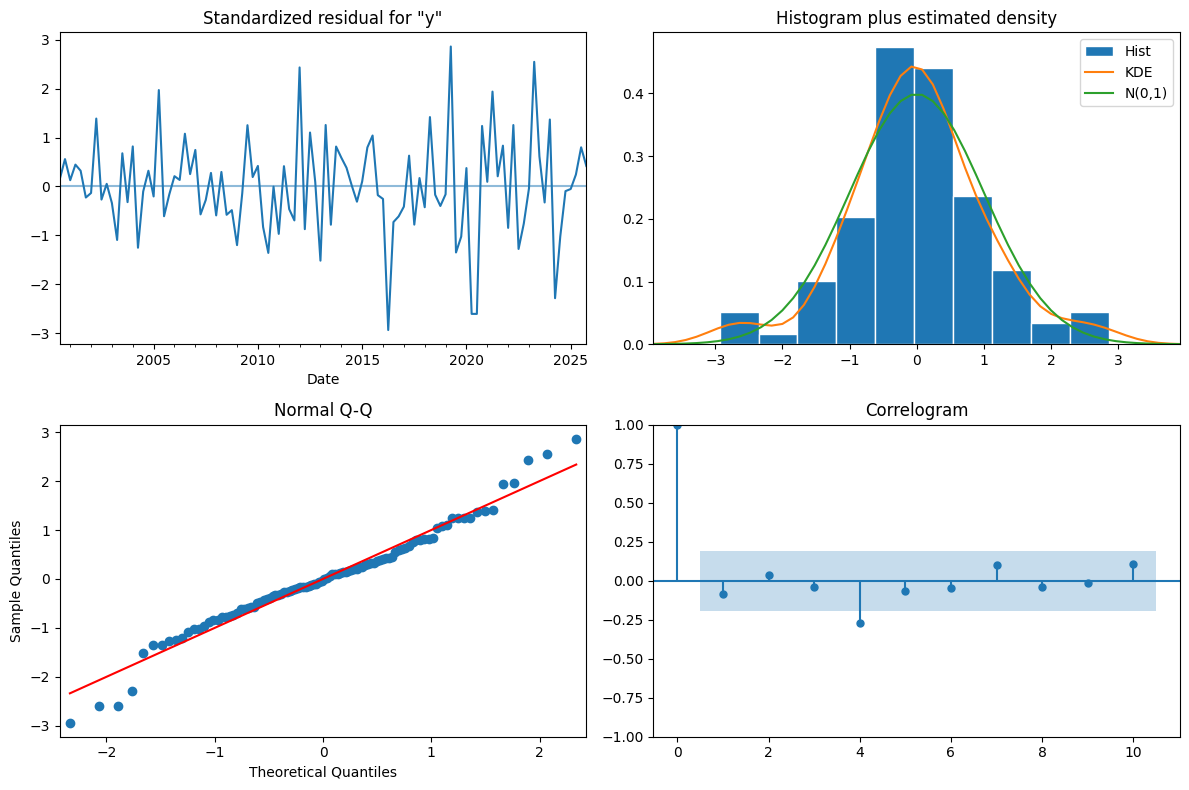

In [33]:
#primera aproximación
fig = resultado.plot_diagnostics(figsize=(12, 8))
plt.tight_layout()
plt.show()

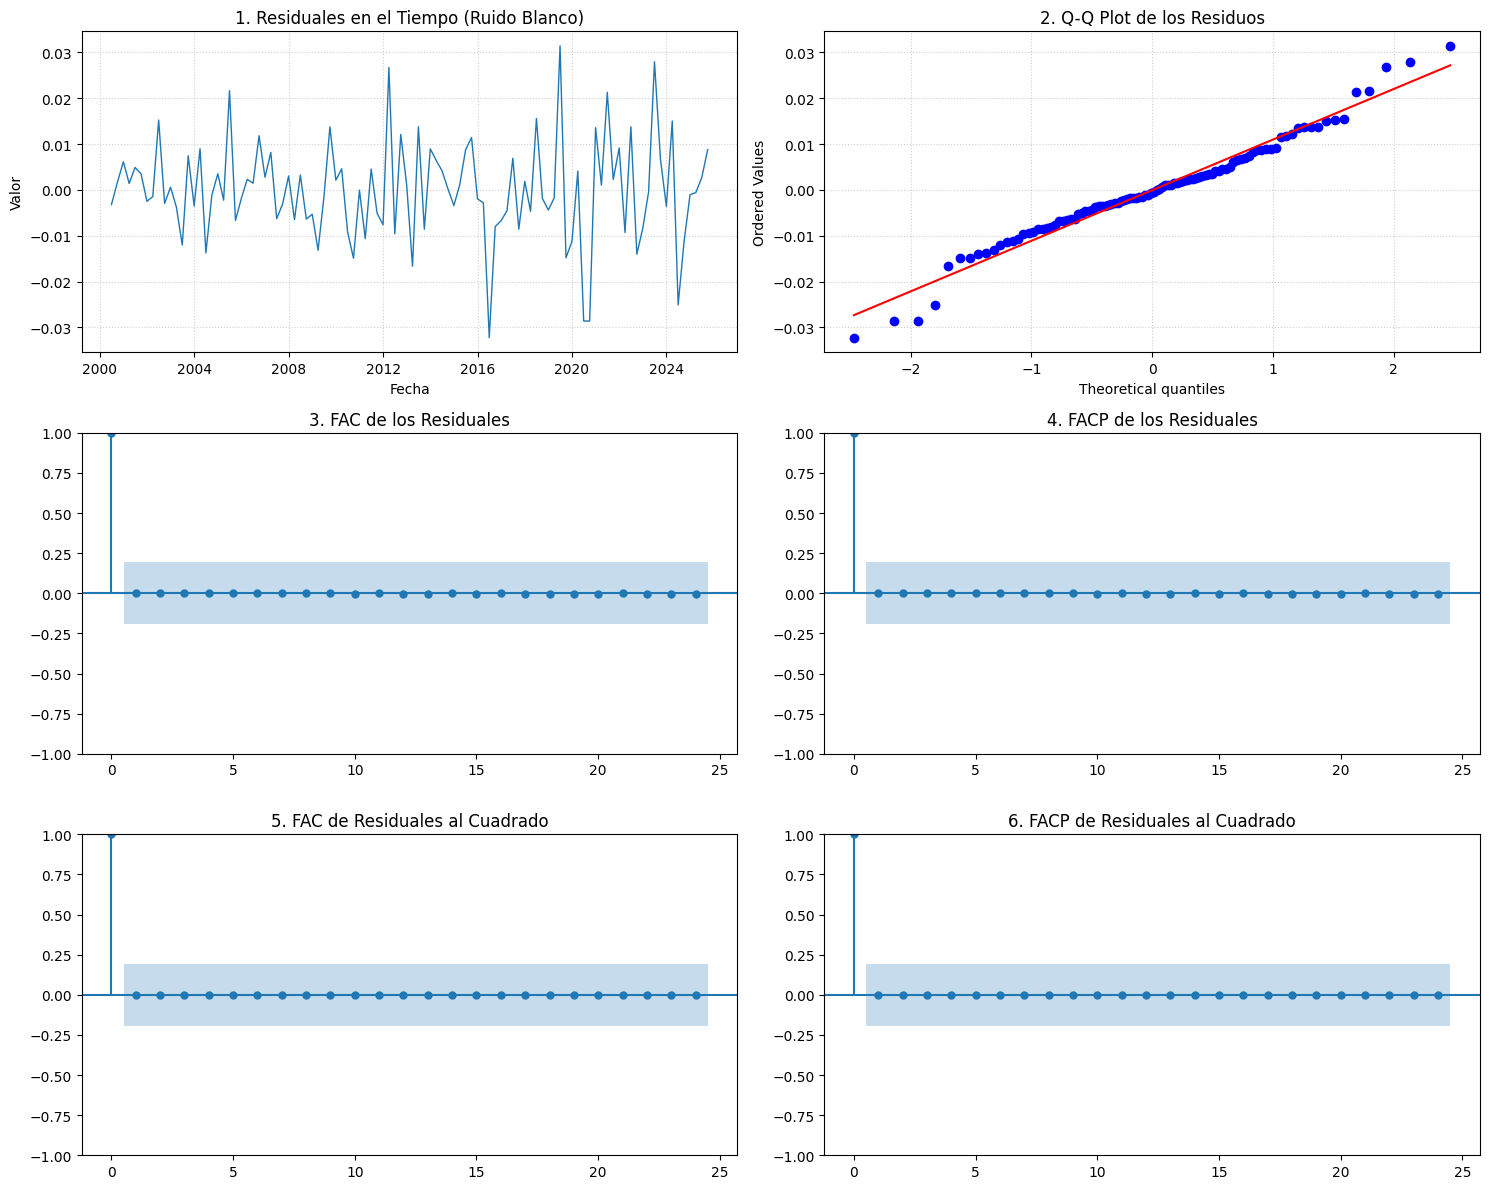

In [34]:
# 1. Extracción de residuales limpios
residuales = resultado.resid.dropna()

# 2. Creación del panel único de gráficas (3 filas x 2 columnas)
fig, axes = plt.subplots(3, 2, figsize=(15, 12))

# --- Gráfica 1: serie_trimestral de tiempo de los residuales ---
axes[0, 0].plot(residuales.iloc[1:-1], color='tab:blue', linewidth=1)
axes[0, 0].set_title("1. Residuales en el Tiempo (Ruido Blanco)")
axes[0, 0].set_xlabel("Fecha")
axes[0, 0].set_ylabel("Valor")
axes[0, 0].grid(True, linestyle=':', alpha=0.6)

# --- Gráfica 2: Q-Q Plot de Normalidad ---
probplot(residuales.iloc[1:-1], dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("2. Q-Q Plot de los Residuos")
axes[0, 1].grid(True, linestyle=':', alpha=0.6)

# --- Gráfica 3: FAC de los residuales ---
plot_acf(
    residuales,
    lags=24,
    alpha=0.05,
    bartlett_confint=False,
    ax=axes[1, 0]
)
axes[1, 0].set_title("3. FAC de los Residuales")

# --- Gráfica 4: FACP de los residuales ---
plot_pacf(
    residuales,
    lags=24,
    alpha=0.05,
    ax=axes[1, 1]
)
axes[1, 1].set_title("4. FACP de los Residuales")

# --- Gráfica 5: FAC de los residuales al cuadrado (Efectos ARCH) ---
plot_acf(
    residuales**2,
    lags=24,
    alpha=0.05,
    bartlett_confint=False,
    ax=axes[2, 0]
)
axes[2, 0].set_title("5. FAC de Residuales al Cuadrado")

# --- Gráfica 6: FACP de los residuales al cuadrado (Efectos ARCH) ---
plot_pacf(
    residuales**2,
    lags=24,
    alpha=0.05,
    ax=axes[2, 1]
)
axes[2, 1].set_title("6. FACP de Residuales al Cuadrado")

plt.tight_layout()
plt.show()



In [35]:
# %% =========================================================================
# PRUEBAS ESTADÍSTICAS FORMALES Y RESUMEN DE DIAGNÓSTICO
# =========================================================================

alpha = 0.05  # Nivel de significancia (5%)

print("=" * 75)
print("              DIAGNÓSTICO FORMAL DE SUPUESTOS ECONOMÉTRICOS")
print("=" * 75)

# -------------------------------------------------------------------------
# 1. PRUEBA DE LJUNG-BOX (Autocorrelación)
# -------------------------------------------------------------------------
print("\n1. PRUEBA DE LJUNG-BOX (Autocorrelación / Independencia)")
print("-" * 75)

ljung_box = acorr_ljungbox(residuales, lags=[6, 12, 18, 24, 48], return_df=True)

# Mostrar resumen compacto en lugar de la tabla extendida
for lag, row in ljung_box.iterrows():
    stat = row['lb_stat']
    pval = row['lb_pvalue']
    print(f"   Lag {lag:2d} -> Estadístico Q: {stat:8.4f} | p-valor: {pval:.4f}")

min_p_lb = ljung_box['lb_pvalue'].min()

if min_p_lb > alpha:
    print(f"\n-> VERDICTO: [✓] CUMPLE el supuesto de No autocorrelación.")
else:
    print(f"\n-> VERDICTO: [X] NO CUMPLE el supuesto de no autocorrelación.")

# -------------------------------------------------------------------------
# 2. PRUEBA DE ENGLE ARCH (Homocedasticidad Condicional)
# -------------------------------------------------------------------------
print("\n" + "=" * 75)
print("2. PRUEBA ENGLE ARCH (Homocedasticidad / Varianza constante)")
print("-" * 75)

arch_test = het_arch(residuales, nlags=12)
lm_stat, lm_pvalue = arch_test[0], arch_test[1]

print(f"   Estadístico LM: {lm_stat:8.4f} | p-valor: {lm_pvalue:.4f}")

if lm_pvalue > alpha:
    print(f"\n-> VERDICTO: [✓] CUMPLE el supuesto de homocedasticidad.")
else:
    print(f"\n-> VERDICTO: [X] NO CUMPLE el supuesto de homocedasticidad (hay efectos ARCH).")

# -------------------------------------------------------------------------
# 3. PRUEBA DE JARQUE-BERA (Normalidad)
# -------------------------------------------------------------------------
print("\n" + "=" * 75)
print("3. PRUEBA DE JARQUE-BERA (Normalidad de los residuos)")
print("-" * 75)

jb_test = jarque_bera(residuales)
jb_stat, jb_pvalue = jb_test.statistic, jb_test.pvalue

print(f"   Estadístico JB: {jb_stat:8.4f} | p-valor: {jb_pvalue:.4f}")

if jb_pvalue > alpha:
    print(f"\n-> VERDICTO: [✓] CUMPLE el supuesto de normalidad.")
else:
    print(f"\n-> VERDICTO: [X] NO CUMPLE el supuesto de normalidad.")

print("=" * 75)

              DIAGNÓSTICO FORMAL DE SUPUESTOS ECONOMÉTRICOS

1. PRUEBA DE LJUNG-BOX (Autocorrelación / Independencia)
---------------------------------------------------------------------------
   Lag  6 -> Estadístico Q:   0.0000 | p-valor: 1.0000
   Lag 12 -> Estadístico Q:   0.0009 | p-valor: 1.0000
   Lag 18 -> Estadístico Q:   0.0036 | p-valor: 1.0000
   Lag 24 -> Estadístico Q:   0.0067 | p-valor: 1.0000
   Lag 48 -> Estadístico Q:   0.0613 | p-valor: 1.0000

-> VERDICTO: [✓] CUMPLE el supuesto de No autocorrelación.

2. PRUEBA ENGLE ARCH (Homocedasticidad / Varianza constante)
---------------------------------------------------------------------------
   Estadístico LM:  16.6385 | p-valor: 0.1637

-> VERDICTO: [✓] CUMPLE el supuesto de homocedasticidad.

3. PRUEBA DE JARQUE-BERA (Normalidad de los residuos)
---------------------------------------------------------------------------
   Estadístico JB: 44203.8355 | p-valor: 0.0000

-> VERDICTO: [X] NO CUMPLE el supuesto de normali

c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


# Pronóstico

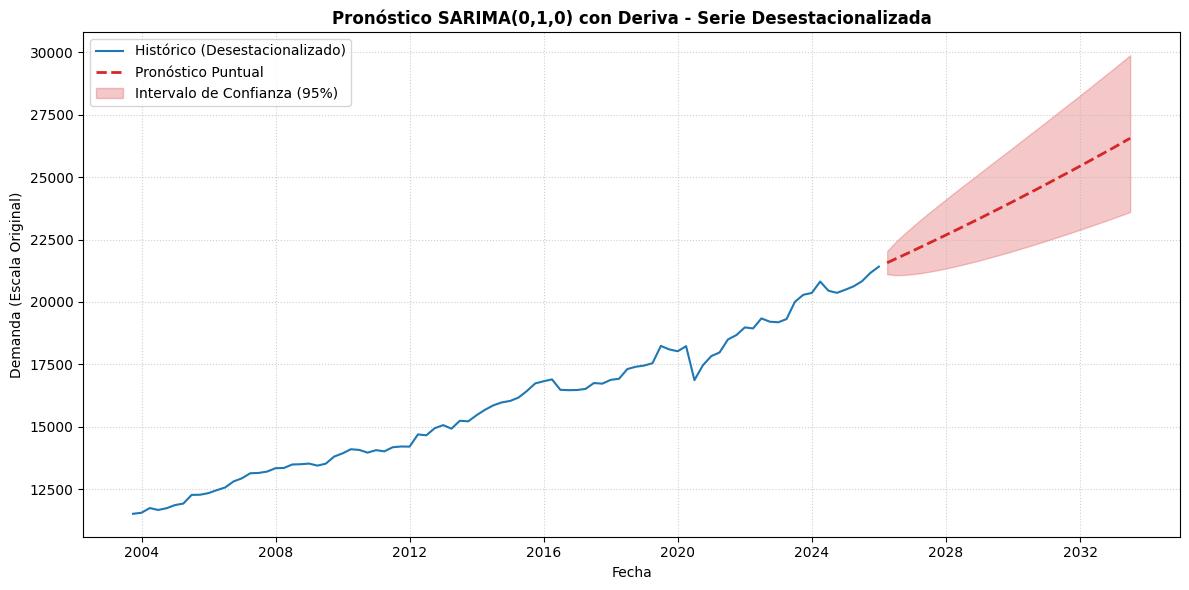

PRONÓSTICOS PARA LOS PRÓXIMOS 30 PERIODOS (ESCALA ORIGINAL)
              Pronostico   IC_Inferior   IC_Superior
2026-03-31  21569.773631  21110.203948  22039.348157
2026-06-30  21725.050586  21073.342862  22396.912823
2026-09-30  21881.445353  21080.255005  22713.086281
2026-12-31  22038.965978  21109.837881  23008.988706
2027-03-31  22197.620566  21153.981779  23292.747623
2027-06-30  22357.417280  21208.559281  23568.508394
2027-09-30  22518.364342  21271.137307  23838.722177
2027-12-31  22680.470034  21340.142950  24104.980091
2028-03-31  22843.742695  21414.492428  24368.384264
2028-06-30  23008.190727  21493.403186  24629.735736
2028-09-30  23173.822591  21576.289540  24889.638808
2028-12-31  23340.646809  21662.700552  25148.563180
2029-03-31  23508.671966  21752.280975  25406.882994
2029-06-30  23677.906705  21844.745606  25664.902491
2029-09-30  23848.359735  21939.861823  25922.873473
2029-12-31  24020.039826  22037.437330  26181.007556
2030-03-31  24192.955811  22137.311334 

In [36]:
# %% =========================================================================
# PRONÓSTICO CON SARIMAX(0,1,0) + DERIVA Y VARIABLE EXÓGENA
# =========================================================================

# 1. Definir el horizonte de pronóstico (pasos hacia el futuro)
h = 30  # Cambia a la cantidad de periodos que deseas proyectar (ej. 30 días, 12 meses)

# 2. Crear la matriz exógena futura
# Al ser una dummy de pandemia, asume valor 0 para los periodos futuros fuera de la muestra.
# Se hereda la frecuencia temporal de la serie original.
frecuencia = pd.infer_freq(log_serie_desestacionalizada.index) or 'D'
fechas_futuras = pd.date_range(
    start=log_serie_desestacionalizada.index[-1],
    periods=h + 1,
    freq=frecuencia,
)[1:]

exog_futuro = pd.DataFrame(
    0, index=fechas_futuras, columns=dummy_pandemia.columns
)

# 3. Generar el pronóstico en escala logarítmica
pronostico_objeto = resultado.get_forecast(steps=h, exog=exog_futuro)
df_log_pred = pronostico_objeto.summary_frame(alpha=0.05)

# 4. Transformar los resultados a la escala original de la serie (Exponencial)
df_pronostico = pd.DataFrame(index=fechas_futuras)
df_pronostico['Pronostico'] = np.exp(df_log_pred['mean'])
df_pronostico['IC_Inferior'] = np.exp(df_log_pred['mean_ci_lower'])
df_pronostico['IC_Superior'] = np.exp(df_log_pred['mean_ci_upper'])

# 5. Visualización gráfica del pronóstico
plt.figure(figsize=(12, 6))

# Mostrar los últimos 90 periodos históricos para contextualizar el gráfico
historico_reciente = np.exp(log_serie_desestacionalizada.tail(90))

plt.plot(
    historico_reciente.index,
    historico_reciente,
    label='Histórico (Desestacionalizado)',
    color='#1f77b4',
    linewidth=1.5,
)
plt.plot(
    df_pronostico.index,
    df_pronostico['Pronostico'],
    label='Pronóstico Puntual',
    color='#d62728',
    linestyle='--',
    linewidth=2,
)
plt.fill_between(
    df_pronostico.index,
    df_pronostico['IC_Inferior'],
    df_pronostico['IC_Superior'],
    color='#d62728',
    alpha=0.25,
    label='Intervalo de Confianza (95%)',
)

plt.title(
    'Pronóstico SARIMA(0,1,0) con Deriva - Serie Desestacionalizada',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Fecha')
plt.ylabel('Demanda (Escala Original)')
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# 6. Desplegar los valores numéricos proyectados
print('=' * 65)
print(f'PRONÓSTICOS PARA LOS PRÓXIMOS {h} PERIODOS (ESCALA ORIGINAL)')
print('=' * 65)
print(df_pronostico)

In [37]:
# %% =========================================================================
# EXTRACCIÓN DE CRITERIOS DE INFORMACIÓN (AIC / BIC) DEL MODELO
# =========================================================================

import pandas as pd
from IPython.display import Markdown, display

# 1. Extraer métricas desde el objeto de resultados
aic_val = resultado.aic
bic_val = resultado.bic
log_likelihood = resultado.llf
num_params = len(resultado.params)

# 2. Despliegue formateado en consola/terminal
df_criterios = pd.DataFrame({
    'Métrica / Criterio': [
        'AIC (Akaike Information Criterion)',
        'BIC (Bayesian Information Criterion)',
        'Log-Likelihood (Log-Verosimilitud)',
        'Parámetros Estimados (k)',
    ],
    'Valor': [f"{aic_val:.4f}", f"{bic_val:.4f}", f"{log_likelihood:.4f}", num_params]
})

print("=" * 60)
print("CRITERIOS DE SELECCIÓN Y AJUSTE DEL MODELO")
print("=" * 60)
print(df_criterios.to_string(index=False))

# 3. Presentación gráfica opcional para Jupyter Notebook (Markdown)
criterios_md = f"""
### 📊 Criterios de Información SARIMAX(0,1,0)

| Criterio / Métrica | Valor |
| :--- | :---: |
| **AIC** (*Akaike Information Criterion*) | **`{aic_val:.4f}`** |
| **BIC** (*Bayesian Information Criterion*) | **`{bic_val:.4f}`** |
| **Log-Likelihood** ($\ell$) | `{log_likelihood:.4f}` |
| **Parámetros estimados** ($k$) | `{num_params}` |

* **AIC / BIC:** Cuanto menor sea el valor, mejor es la capacidad relativa del modelo para explicarlos con eficiencia sin incurrir en sobreajuste (*overfitting*). El **BIC** penaliza con mayor severidad la inclusión de nuevos parámetros que el AIC.
"""

display(Markdown(criterios_md))

CRITERIOS DE SELECCIÓN Y AJUSTE DEL MODELO
                  Métrica / Criterio     Valor
  AIC (Akaike Information Criterion) -624.6767
BIC (Bayesian Information Criterion) -616.8017
  Log-Likelihood (Log-Verosimilitud)  315.3383
            Parámetros Estimados (k)         3


<>:43: SyntaxWarning: invalid escape sequence '\e'
<>:43: SyntaxWarning: invalid escape sequence '\e'
C:\Users\Kayak\AppData\Local\Temp\ipykernel_11204\3883942745.py:43: SyntaxWarning: invalid escape sequence '\e'
  



### 📊 Criterios de Información SARIMAX(0,1,0)

| Criterio / Métrica | Valor |
| :--- | :---: |
| **AIC** (*Akaike Information Criterion*) | **`-624.6767`** |
| **BIC** (*Bayesian Information Criterion*) | **`-616.8017`** |
| **Log-Likelihood** ($\ell$) | `315.3383` |
| **Parámetros estimados** ($k$) | `3` |

* **AIC / BIC:** Cuanto menor sea el valor, mejor es la capacidad relativa del modelo para explicarlos con eficiencia sin incurrir en sobreajuste (*overfitting*). El **BIC** penaliza con mayor severidad la inclusión de nuevos parámetros que el AIC.


In [38]:
# ==========%% Gráfica de la serie trimestral  %%==============#
"""plt.figure(figsize=(10, 6))
plt.plot(serie_trimestral, color='blue', linewidth=2, marker='o', label='Demanda Trimestral')
plt.title('Serie Trimestral de Tiempo: Demanda Energía SIN (Suma Trimestral 2000-2025)')
plt.xlabel('Tiempo')
plt.ylabel('Escala Logarítmica')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()"""

"plt.figure(figsize=(10, 6))\nplt.plot(serie_trimestral, color='blue', linewidth=2, marker='o', label='Demanda Trimestral')\nplt.title('Serie Trimestral de Tiempo: Demanda Energía SIN (Suma Trimestral 2000-2025)')\nplt.xlabel('Tiempo')\nplt.ylabel('Escala Logarítmica')\nplt.grid(True, linestyle='--', alpha=0.5)\nplt.legend()\nplt.show()"